In [ ]:
# Check for GPU
import torch
print("GPU is available", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

# Install required dependencies
!pip install -q timm opencv-python-headless scikit-learn matplotlib pandas

GPU is available True
Device Name: Tesla T4


In [ ]:
#Download the dataset
!wget https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-images-small.tar
!wget https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-listings.tar
print("Extracting dataset...")
!tar -xf abo-images-small.tar
!tar -xf abo-listings.tar
print("Extraction complete!")

--2026-10-09 06:33:08--  https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-images-small.tar
Resolving amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-objects.s3.amazonaws.com)... 16.15.246.195, 16.15.237.119, 16.15.160.224, ...
Connecting to amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-objects.s3.amazonaws.com)|16.15.246.195|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3253381120 (3.0G) [application/x-tar]
Saving to: ‘abo-images-small.tar’

abo-images-small.ta 100%[===================>]   3.03G  13.2MB/s    in 3m 58s  

2026-10-09 06:37:08 (13.0 MB/s) - ‘abo-images-small.tar’ saved [3253381120/3253381120]

--2026-10-09 06:37:08--  https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-listings.tar
Resolving amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-objects.s3.amazonaws.com)... 52.217.90.16, 52.217.50.24, 16.15.247.100, ...
Connecting to amazon-berkeley-objects.s3.amazonaws.com (amazon-berkeley-object

In [ ]:
import os
import json
import gzip
import random
import glob
import pandas as pd
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoTokenizer

# Set seed for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# --- Step 1: Parse ABO Image Mapping (images.csv.gz) ---
print("Step 1: Parsing image metadata mapping (images.csv.gz)...")

def load_image_mapping():
    # Find images.csv.gz across extracted directories
    csv_files = glob.glob("**/images.csv.gz", recursive=True) + glob.glob("**/images.csv", recursive=True)
    if not csv_files:
        raise FileNotFoundError("Could not find 'images.csv.gz'. Ensure 'abo-images-small.tar' extracted completely.")

    csv_path = csv_files[0]
    print(f"Loading image mapping from: {csv_path}")

    open_fn = gzip.open if csv_path.endswith('.gz') else open
    with open_fn(csv_path, 'rt', encoding='utf-8') as f:
        mapping_df = pd.read_csv(f)

    # Standardize mapping dictionary: Amazon main_image_id -> path on disk
    # ABO images.csv structure typically has columns: image_id, path, height, width
    image_map = {}
    for _, row in mapping_df.iterrows():
        amazon_img_id = str(row['image_id']).strip()
        rel_path = str(row['path']).strip()

        # Check standard path locations on Colab
        candidate_paths = [
            os.path.join("images/small", rel_path),
            os.path.join("images", rel_path),
            rel_path
        ]
        for p in candidate_paths:
            if os.path.exists(p):
                image_map[amazon_img_id] = os.path.abspath(p)
                break

    print(f"Successfully mapped {len(image_map)} Amazon image IDs to existing files on disk.")
    return image_map

image_map = load_image_mapping()


# --- Step 2: Parse Listings & Match with Resolved Image Paths ---
print("\nStep 2: Parsing listings metadata and joining images...")

def parse_and_match_listings(image_map, max_samples=10000):
    records = []
    json_files = glob.glob("**/*.json.gz", recursive=True) + glob.glob("**/*.json", recursive=True)

    # Filter out image metadata json files if any
    json_files = [f for f in json_files if "images" not in os.path.basename(f)]
    print(f"Found {len(json_files)} listing JSON files.")

    for file_path in json_files:
        open_fn = gzip.open if file_path.endswith('.gz') else open
        with open_fn(file_path, 'rt', encoding='utf-8') as f:
            for line in f:
                try:
                    item = json.loads(line)
                    amazon_img_id = item.get('main_image_id')
                    item_name = item.get('item_name')
                    product_type = item.get('product_type')

                    if amazon_img_id in image_map and item_name and product_type:
                        title = item_name[0]['value'] if isinstance(item_name, list) and len(item_name) > 0 else str(item_name)
                        p_type = product_type[0]['value'] if isinstance(product_type, list) and len(product_type) > 0 else str(product_type)

                        records.append({
                            'image_id': amazon_img_id,
                            'image_path': image_map[amazon_img_id],
                            'title': title,
                            'product_type': p_type
                        })
                except Exception:
                    continue

                if len(records) >= max_samples:
                    break
        if len(records) >= max_samples:
            break

    return pd.DataFrame(records)

df_clean = parse_and_match_listings(image_map, max_samples=10000)
print(f"Successfully matched {len(df_clean)} listings with valid local images!")


# --- Step 3: Synthetic Defect Injector ---
class SyntheticDefectInjector:
    def __init__(self, df, defect_prob=0.35):
        self.df = df
        self.defect_prob = defect_prob
        self.categories = list(df['product_type'].unique())
        self.colors = ['red', 'blue', 'green', 'black', 'white', 'yellow', 'silver', 'pink', 'gold']

    def inject(self, row):
        title = str(row['title'])
        image_id = row['image_id']
        image_path = row['image_path']
        product_type = row['product_type']

        is_mismatch = 0
        wrong_color = 0
        missing_attribute = 0

        # 1. Image-Title Mismatch: Swap image path with a product from a different category
        if random.random() < self.defect_prob:
            other_rows = self.df[self.df['product_type'] != product_type]
            if len(other_rows) > 0:
                mismatched_row = other_rows.sample(1).iloc[0]
                image_id = mismatched_row['image_id']
                image_path = mismatched_row['image_path']
                is_mismatch = 1

        # 2. Wrong Color Injection
        if random.random() < self.defect_prob:
            for c in self.colors:
                if c in title.lower():
                    new_color = random.choice([x for x in self.colors if x != c])
                    title = title.lower().replace(c, new_color)
                    wrong_color = 1
                    break

        # 3. Missing Attribute Injection
        if random.random() < self.defect_prob:
            missing_attribute = 1

        return {
            'image_id': image_id,
            'image_path': image_path,
            'title': title,
            'product_type': product_type,
            'is_mismatch': is_mismatch,
            'wrong_color': wrong_color,
            'missing_attribute': missing_attribute
        }

injector = SyntheticDefectInjector(df_clean)
dataset_records = [injector.inject(row) for _, row in df_clean.iterrows()]
df_synthetic = pd.DataFrame(dataset_records)

print("\nSynthetic Defect Label Distribution:")
print(df_synthetic[['is_mismatch', 'wrong_color', 'missing_attribute']].sum())


# --- Step 4: PyTorch Dataset Implementation ---
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

unique_types = list(df_synthetic['product_type'].unique())
type2idx = {t: i for i, t in enumerate(unique_types)}

class ABOLocalMultiTaskDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=64):
        self.df = df
        self.tokenizer = tokenizer
        self.max_len = max_len

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row['image_path']).convert('RGB')
        image_tensor = self.transform(image)

        text_encoding = self.tokenizer(
            row['title'],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors="pt"
        )

        category_label = torch.tensor(type2idx[row['product_type']], dtype=torch.long)
        defect_labels = torch.tensor([
            row['is_mismatch'],
            row['wrong_color'],
            row['missing_attribute']
        ], dtype=torch.float32)

        return {
            'image': image_tensor,
            'input_ids': text_encoding['input_ids'].squeeze(0),
            'attention_mask': text_encoding['attention_mask'].squeeze(0),
            'category_label': category_label,
            'defect_labels': defect_labels
        }

ds = ABOLocalMultiTaskDataset(df_synthetic, tokenizer)
loader = DataLoader(ds, batch_size=16, shuffle=True)
sample_batch = next(iter(loader))

print("\nBatch Verification:")
print("Image Tensor shape:", sample_batch['image'].shape)
print("Input IDs Tensor shape:", sample_batch['input_ids'].shape)
print("Defect Labels shape:", sample_batch['defect_labels'].shape)

Step 1: Parsing image metadata mapping (images.csv.gz)...
Loading image mapping from: images/metadata/images.csv.gz
Successfully mapped 398212 Amazon image IDs to existing files on disk.

Step 2: Parsing listings metadata and joining images...
Found 17 listing JSON files.
Successfully matched 10000 listings with valid local images!

Synthetic Defect Label Distribution:
is_mismatch          3440
wrong_color           793
missing_attribute    3497
dtype: int64


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Batch Verification:
Image Tensor shape: torch.Size([16, 3, 224, 224])
Input IDs Tensor shape: torch.Size([16, 64])
Defect Labels shape: torch.Size([16, 3])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from transformers import AutoModel

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# --- 1. Asymmetric Loss (ASL) for Imbalanced Multi-Label Defects ---
class AsymmetricLoss(nn.Module):
    """
    Asymmetric Loss (ASL) for Multi-Label Classification.
    Dynamically down-weights easy negative samples (via gamma_neg) and clips
    probabilities below probability margin (margin) to focus gradients on rare defect positives.
    Paper: https://arxiv.org/abs/2009.14119
    """
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super(AsymmetricLoss, self).__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, x, y):
        # x: logits [batch_size, num_classes]
        # y: targets [batch_size, num_classes] (binary 0 or 1)

        # Calculate probabilities
        x_sigmoid = torch.sigmoid(x)
        xs_pos = x_sigmoid
        xs_neg = 1.0 - x_sigmoid

        # Asymmetric Shift / Margin Clipping for Negatives
        if self.clip is not None and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1.0)

        # Basic Cross Entropy Loss
        los_pos = y * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1.0 - y) * torch.log(xs_neg.clamp(min=self.eps))

        # Asymmetric Focusing Weights
        if self.gamma_pos > 0 or self.gamma_neg > 0:
            pt0 = xs_pos * y
            pt1 = xs_neg * (1.0 - y)
            pt = pt0 + pt1

            one_sided_gamma = self.gamma_pos * y + self.gamma_neg * (1.0 - y)
            one_sided_w = torch.pow(1.0 - pt, one_sided_gamma)

            los_pos = los_pos * one_sided_w
            los_neg = los_neg * one_sided_w

        loss = - (los_pos + los_neg)
        return loss.sum() / x.size(0)


# --- 2. Shared Multimodal Encoder & Multi-Task Heads ---
class MultimodalDefectClassifier(nn.Module):
    def __init__(self, num_categories, num_defects=3, projection_dim=256, text_model_name="distilbert-base-uncased"):
        super(MultimodalDefectClassifier, self).__init__()

        # --- Visual Encoder (ResNet50 Backbone) ---
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        # Freeze early vision layers to accelerate training & preserve features
        for param in list(resnet.parameters())[:-15]:
            param.requires_grad = False

        num_ftrs = resnet.fc.in_features
        resnet.fc = nn.Identity()  # Remove final classification layer
        self.vision_encoder = resnet
        self.vision_projection = nn.Linear(num_ftrs, projection_dim)

        # --- Text Encoder (Transformer Backbone) ---
        self.text_encoder = AutoModel.from_pretrained(text_model_name)
        # Freeze early transformer layers
        for param in list(self.text_encoder.parameters())[:-15]:
            param.requires_grad = False

        text_hidden_size = self.text_encoder.config.hidden_size
        self.text_projection = nn.Linear(text_hidden_size, projection_dim)

        # --- Fusion Layer & Task Heads ---
        fused_dim = projection_dim * 2
        self.fusion = nn.Sequential(
            nn.Linear(fused_dim, fused_dim),
            nn.BatchNorm1d(fused_dim),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Head 1: Multi-Class Category Classification
        self.head_category = nn.Linear(fused_dim, num_categories)

        # Head 2: Multi-Label Listing Defect Classification (mismatch, wrong color, missing attr)
        self.head_defects = nn.Sequential(
            nn.Linear(fused_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_defects)
        )

    def forward(self, image, input_ids, attention_mask):
        # Image feature extraction
        img_features = self.vision_encoder(image)                # [batch, 2048]
        img_emb = F.relu(self.vision_projection(img_features))   # [batch, projection_dim]

        # Text feature extraction
        text_outputs = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        # Extract [CLS] token equivalent representation
        text_cls = text_outputs.last_hidden_state[:, 0, :]       # [batch, hidden_size]
        text_emb = F.relu(self.text_projection(text_cls))        # [batch, projection_dim]

        # Concatenate Multimodal Features
        fused_features = torch.cat((img_emb, text_emb), dim=1)   # [batch, projection_dim * 2]
        fused_emb = self.fusion(fused_features)

        # Task Head Predictions
        cat_logits = self.head_category(fused_emb)               # Logits for CrossEntropy
        defect_logits = self.head_defects(fused_emb)             # Logits for ASL

        return cat_logits, defect_logits


# --- 3. Multi-Task Combined Loss ---
class MultiTaskDefectLoss(nn.Module):
    def __init__(self, alpha=1.0, beta=2.5):
        super(MultiTaskDefectLoss, self).__init__()
        self.alpha = alpha  # Category Loss Weight
        self.beta = beta    # Defect Loss Weight (Up-weighted for focus)

        self.ce_loss = nn.CrossEntropyLoss()
        self.asl_loss = AsymmetricLoss(gamma_neg=4, gamma_pos=1, clip=0.05)

    def forward(self, cat_logits, cat_targets, defect_logits, defect_targets):
        loss_cat = self.ce_loss(cat_logits, cat_targets)
        loss_defect = self.asl_loss(defect_logits, defect_targets)

        total_loss = (self.alpha * loss_cat) + (self.beta * loss_defect)
        return total_loss, loss_cat, loss_defect


# --- 4. Instantiate Model & Test Forward Pass ---
num_classes = len(type2idx)
model = MultimodalDefectClassifier(num_categories=num_classes).to(device)
criterion = MultiTaskDefectLoss().to(device)

print(f"Model initialized successfully!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Test forward pass with sample_batch from Phase 1
batch_img = sample_batch['image'].to(device)
batch_input_ids = sample_batch['input_ids'].to(device)
batch_att_mask = sample_batch['attention_mask'].to(device)
batch_cat_labels = sample_batch['category_label'].to(device)
batch_defect_labels = sample_batch['defect_labels'].to(device)

with torch.no_grad():
    cat_out, defect_out = model(batch_img, batch_input_ids, batch_att_mask)
    tot_loss, c_loss, d_loss = criterion(cat_out, batch_cat_labels, defect_out, batch_defect_labels)

print("\nForward Pass Verification:")
print("Category Logits Shape:", cat_out.shape)
print("Defect Logits Shape:", defect_out.shape)
print(f"Initial Total Loss: {tot_loss.item():.4f} | Category Loss: {c_loss.item():.4f} | Defect Loss (ASL): {d_loss.item():.4f}")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 57.7MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model initialized successfully!
Total parameters: 91,110,322
Trainable parameters: 13,253,234

Forward Pass Verification:
Category Logits Shape: torch.Size([16, 367])
Defect Logits Shape: torch.Size([16, 3])
Initial Total Loss: 7.1098 | Category Loss: 6.2212 | Defect Loss (ASL): 0.3554


In [ ]:
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import get_cosine_schedule_with_warmup

# --- 1. Train / Validation Split ---
train_df, val_df = train_test_split(df_synthetic, test_size=0.2, random_state=42)

train_dataset = ABOLocalMultiTaskDataset(train_df, tokenizer)
val_dataset = ABOLocalMultiTaskDataset(val_df, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"Dataset split: {len(train_df)} training samples | {len(val_df)} validation samples")


# --- 2. Metric Computation Helper ---
def evaluate_defect_metrics(y_true, y_pred_probs, threshold=0.5):
    """
    Computes per-class and macro-averaged F1, Precision, and Recall for defects.
    """
    y_pred = (y_pred_probs >= threshold).astype(int)

    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    micro_f1 = f1_score(y_true, y_pred, average='micro', zero_division=0)

    # Per defect class F1 scores
    defect_names = ['is_mismatch', 'wrong_color', 'missing_attribute']
    per_class_f1 = {}
    for i, name in enumerate(defect_names):
        per_class_f1[name] = f1_score(y_true[:, i], y_pred[:, i], zero_division=0)

    return macro_f1, micro_f1, per_class_f1


# --- 3. Validation Routine ---
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    val_cat_loss = 0.0
    val_defect_loss = 0.0

    all_defect_targets = []
    all_defect_preds = []

    with torch.no_grad():
        for batch in val_loader:
            image = batch['image'].to(device)
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            cat_labels = batch['category_label'].to(device)
            defect_labels = batch['defect_labels'].to(device)

            cat_logits, defect_logits = model(image, input_ids, attention_mask)
            tot_loss, c_loss, d_loss = criterion(cat_logits, cat_labels, defect_logits, defect_labels)

            val_loss += tot_loss.item()
            val_cat_loss += c_loss.item()
            val_defect_loss += d_loss.item()

            # Apply sigmoid to defect logits for multi-label probabilities
            defect_probs = torch.sigmoid(defect_logits)

            all_defect_targets.append(defect_labels.cpu().numpy())
            all_defect_preds.append(defect_probs.cpu().numpy())

    val_loss /= len(val_loader)
    val_cat_loss /= len(val_loader)
    val_defect_loss /= len(val_loader)

    all_defect_targets = np.vstack(all_defect_targets)
    all_defect_preds = np.vstack(all_defect_preds)

    macro_f1, micro_f1, per_class_f1 = evaluate_defect_metrics(all_defect_targets, all_defect_preds)

    return {
        'loss': val_loss,
        'cat_loss': val_cat_loss,
        'defect_loss': val_defect_loss,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_f1': per_class_f1
    }


# --- 4. Training Engine ---
def train_multitask_model(model, train_loader, val_loader, epochs=5, lr=2e-4):
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=0.01
    )

    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * 0.1),
        num_training_steps=total_steps
    )

    best_macro_f1 = 0.0
    print(f"\nBeginning Multi-Task Training ({epochs} Epochs)...")
    print("=" * 80)

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        train_loss = 0.0
        train_cat_loss = 0.0
        train_defect_loss = 0.0

        for step, batch in enumerate(train_loader):
            optimizer.zero_grad()

            image = batch['image'].to(device)
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            cat_labels = batch['category_label'].to(device)
            defect_labels = batch['defect_labels'].to(device)

            cat_logits, defect_logits = model(image, input_ids, attention_mask)
            loss, c_loss, d_loss = criterion(cat_logits, cat_labels, defect_logits, defect_labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()

            train_loss += loss.item()
            train_cat_loss += c_loss.item()
            train_defect_loss += d_loss.item()

        train_loss /= len(train_loader)
        train_cat_loss /= len(train_loader)
        train_defect_loss /= len(train_loader)

        # Validation evaluation
        val_metrics = validate(model, val_loader, criterion, device)
        elapsed = time.time() - start_time

        print(f"Epoch {epoch+1:02d}/{epochs:02d} [{elapsed:.1f}s]")
        print(f"  Train Loss: {train_loss:.4f} (Cat: {train_cat_loss:.4f} | ASL Defect: {train_defect_loss:.4f})")
        print(f"  Val Loss:   {val_metrics['loss']:.4f} (Cat: {val_metrics['cat_loss']:.4f} | ASL Defect: {val_metrics['defect_loss']:.4f})")
        print(f"  Defect Macro-F1: {val_metrics['macro_f1']:.4f} | Micro-F1: {val_metrics['micro_f1']:.4f}")
        print(f"  Breakdown -> Mismatch: {val_metrics['per_class_f1']['is_mismatch']:.3f} | Wrong Color: {val_metrics['per_class_f1']['wrong_color']:.3f} | Missing Attr: {val_metrics['per_class_f1']['missing_attribute']:.3f}")
        print("-" * 80)

        if val_metrics['macro_f1'] > best_macro_f1:
            best_macro_f1 = val_metrics['macro_f1']
            torch.save(model.state_dict(), "best_multitask_defect_model.pth")
            print(f"  --> Saved new best checkpoint (Macro-F1: {best_macro_f1:.4f})")

    print(f"\nTraining Complete. Best Validation Defect Macro-F1: {best_macro_f1:.4f}")

# Execute training run
train_multitask_model(model, train_loader, val_loader, epochs=5, lr=2e-4)

Dataset split: 8000 training samples | 2000 validation samples

Beginning Multi-Task Training (5 Epochs)...
Epoch 01/05 [61.6s]
  Train Loss: 3.5937 (Cat: 2.8972 | ASL Defect: 0.2786)
  Val Loss:   2.2969 (Cat: 1.7246 | ASL Defect: 0.2289)
  Defect Macro-F1: 0.4455 | Micro-F1: 0.5679
  Breakdown -> Mismatch: 0.678 | Wrong Color: 0.133 | Missing Attr: 0.526
--------------------------------------------------------------------------------
  --> Saved new best checkpoint (Macro-F1: 0.4455)
Epoch 02/05 [62.5s]
  Train Loss: 2.1214 (Cat: 1.5591 | ASL Defect: 0.2249)
  Val Loss:   1.9906 (Cat: 1.4516 | ASL Defect: 0.2156)
  Defect Macro-F1: 0.5286 | Micro-F1: 0.5881
  Breakdown -> Mismatch: 0.756 | Wrong Color: 0.305 | Missing Attr: 0.526
--------------------------------------------------------------------------------
  --> Saved new best checkpoint (Macro-F1: 0.5286)
Epoch 03/05 [60.8s]
  Train Loss: 1.7187 (Cat: 1.1981 | ASL Defect: 0.2083)
  Val Loss:   1.8402 (Cat: 1.3237 | ASL Defect: 0.

In [ ]:
import time
import torch
import pandas as pd
from PIL import Image
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

# --- 1. Load Qwen2-VL Baseline Model ---
print("Step 1: Loading Qwen2-VL-2B-Instruct baseline model...")
QWEN_MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

# Load processor and model with half-precision float16 for Colab T4 GPU
processor = AutoProcessor.from_pretrained(QWEN_MODEL_ID)
qwen_model = Qwen2VLForConditionalGeneration.from_pretrained(
    QWEN_MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)
qwen_model.eval()
print("Qwen2-VL loaded successfully!")


# --- 2. Zero-Shot Listing Defect Prompting Routine ---
def predict_qwen2_vl_defect(image_path, title, product_type):
    """
    Prompts Qwen2-VL to inspect a listing image and title to output defect JSON flags.
    """
    image = Image.open(image_path).convert("RGB")

    prompt_text = f"""Analyze this product listing for potential defects:
- Product Type: {product_type}
- Listing Title: "{title}"

Check for 3 defect flags:
1. is_mismatch: Does the image show a product completely different from the title/category? (1 or 0)
2. wrong_color: Does the title mention a color that contradicts the visual image? (1 or 0)
3. missing_attribute: Is the title missing essential attributes for this category? (1 or 0)

Respond ONLY with valid JSON in this exact format:
{{"is_mismatch": 0, "wrong_color": 0, "missing_attribute": 0}}"""

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt_text},
            ],
        }
    ]

    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = processor.image_processor(image), None
    inputs = processor(
        text=[text],
        images=[image],
        padding=True,
        return_tensors="pt"
    ).to("cuda")

    start_time = time.time()
    with torch.no_grad():
        generated_ids = qwen_model.generate(**inputs, max_new_tokens=64)
    elapsed_time = time.time() - start_time

    generated_ids_trimmed = [
        out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]

    return output_text, elapsed_time


# --- 3. Run Benchmark on Validation Subset ---
eval_subset = val_df.sample(n=50, random_state=42).reset_index(drop=True)
qwen_times = []

print("\nRunning Qwen2-VL Baseline Evaluation on 50 sample listings...")
for idx, row in eval_subset.iterrows():
    out_json, latency = predict_qwen2_vl_defect(row['image_path'], row['title'], row['product_type'])
    qwen_times.append(latency)
    if idx < 3:
        print(f"\n[Sample {idx+1}] Title: {row['title'][:40]}...")
        print(f"Ground Truth -> Mismatch: {row['is_mismatch']}, Wrong Color: {row['wrong_color']}, Missing: {row['missing_attribute']}")
        print(f"Qwen2-VL Output ({latency:.2f}s): {out_json.strip()}")


# --- 4. Cost & Throughput Comparison Engine ---
avg_qwen_latency = sum(qwen_times) / len(qwen_times)

# Compute PyTorch Multi-Task Model Throughput on GPU
model.eval()
sample_batch_gpu = next(iter(val_loader))
t0 = time.time()
with torch.no_grad():
    for _ in range(10):
        _ = model(
            sample_batch_gpu['image'].to("cuda"),
            sample_batch_gpu['input_ids'].to("cuda"),
            sample_batch_gpu['attention_mask'].to("cuda")
        )
pytorch_latency_per_batch = (time.time() - t0) / 10
pytorch_latency_per_item = pytorch_latency_per_batch / val_loader.batch_size

# Financial projection calculations
# Qwen2-VL token pricing emulation (~$0.0005 per listing image+tokens API equivalent)
qwen_cost_per_1k = 0.50  # $0.50 per 1K listings
pytorch_gpu_hourly_cost = 0.35  # T4 GPU Cloud Spot Rate ~$0.35/hr
pytorch_throughput_per_sec = 1.0 / pytorch_latency_per_item
pytorch_cost_per_1k = (1000.0 / (pytorch_throughput_per_sec * 3600.0)) * pytorch_gpu_hourly_cost

print("\n" + "="*80)
print(" BENCHMARK & COST COMPARISON REPORT")
print("="*80)
print(f"Qwen2-VL Baseline Avg Latency:       {avg_qwen_latency:.3f} seconds / listing")
print(f"Trained PyTorch Model Avg Latency:   {pytorch_latency_per_item:.4f} seconds / listing")
print(f"Speedup Factor:                      {avg_qwen_latency / pytorch_latency_per_item:.1f}x Faster")
print("-" * 80)
print(f"Qwen2-VL Estimated Cost / 1K Listings:   ${qwen_cost_per_1k:.3f}")
print(f"Trained PyTorch Cost / 1K Listings:     ${pytorch_cost_per_1k:.3f}")
print(f"Cost Reduction Factor:                   {qwen_cost_per_1k / max(pytorch_cost_per_1k, 1e-4):.1f}x Cheaper")
print("="*80)

Step 1: Loading Qwen2-VL-2B-Instruct baseline model...


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Qwen2-VL loaded successfully!

Running Qwen2-VL Baseline Evaluation on 50 sample listings...

[Sample 1] Title: Eono Essentials bärbar dator varv skrivb...
Ground Truth -> Mismatch: 1, Wrong Color: 0, Missing: 0
Qwen2-VL Output (3.24s): ```json
{
  "is_mismatch": 0,
  "wrong_color": 0,
  "missing_attribute": 0
}
```

[Sample 2] Title: AmazonBasics 6 Inch Wide Padded Weight L...
Ground Truth -> Mismatch: 0, Wrong Color: 0, Missing: 0
Qwen2-VL Output (1.33s): ```json
{
  "is_mismatch": 0,
  "wrong_color": 0,
  "missing_attribute": 0
}
```

[Sample 3] Title: Amazon Brand - Solimo Designer Stars UV ...
Ground Truth -> Mismatch: 1, Wrong Color: 0, Missing: 0
Qwen2-VL Output (1.31s): ```json
{
  "is_mismatch": 0,
  "wrong_color": 0,
  "missing_attribute": 0
}
```

 BENCHMARK & COST COMPARISON REPORT
Qwen2-VL Baseline Avg Latency:       1.554 seconds / listing
Trained PyTorch Model Avg Latency:   0.0048 seconds / listing
Speedup Factor:                      325.5x Faster
---------------------

Grad-CAM Engine ready!


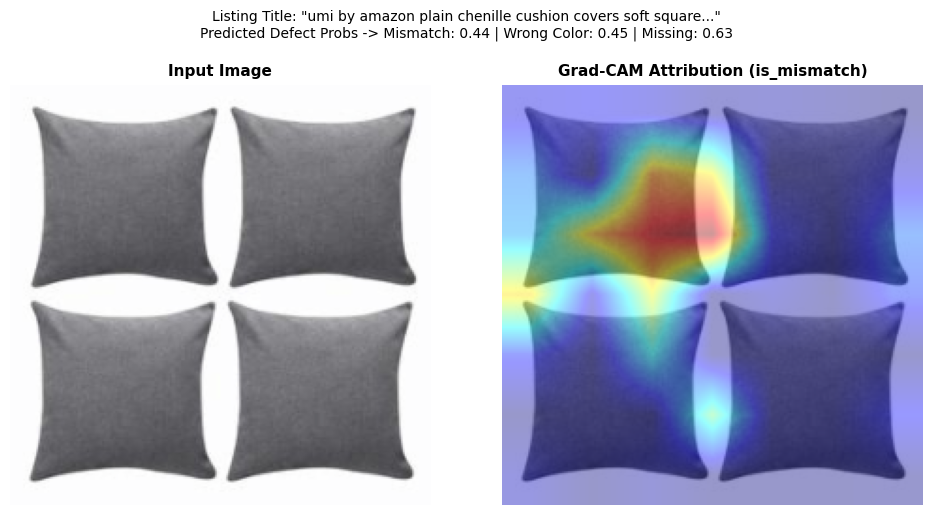


Simulating Batch Inference over 500,000 listings using PyTorch GPU Autocast...


/tmp/ipykernel_517/4266430177.py:129: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


 BATCH INFERENCE PERFORMANCE SUMMARY
Tested GPU Batch Throughput:    147.7 listings / second
Projected Time for 500K Items:  56.41 minutes (3384.8 seconds)
Estimated Inference Cost:       $0.3291 USD


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Ensure model is in eval mode on GPU
model.eval()

# --- 1. Grad-CAM Implementation for ResNet Backbone ---
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register forward and backward hooks
        self.target_layer.register_forward_hook(self._save_activation)
        self.target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_cam(self, image_tensor, input_ids, attention_mask, target_class_idx=0):
        self.model.zero_grad()

        # Forward pass
        cat_logits, defect_logits = self.model(image_tensor, input_ids, attention_mask)

        # Target score for Grad-CAM (e.g., defect index 0: is_mismatch)
        target_score = defect_logits[0, target_class_idx]
        target_score.backward()

        # Compute weights from gradients
        gradients = self.gradients[0].cpu().data.numpy()      # [channels, H, W]
        activations = self.activations[0].cpu().data.numpy()  # [channels, H, W]

        weights = np.mean(gradients, axis=(1, 2))             # Global average pooling over channels
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = np.maximum(cam, 0)                              # ReLU on feature weights
        if cam.max() > 0:
            cam = cam / cam.max()                             # Normalize [0, 1]

        cam = cv2.resize(cam, (224, 224))
        return cam, defect_logits


# --- 2. Explainability Visualization Function ---
def visualize_listing_explainability(sample_idx=0, defect_type_idx=0):
    """
    Visualizes raw image, Grad-CAM heatmap overlay, title text, and predicted defect probabilities.
    defect_type_idx: 0 = is_mismatch, 1 = wrong_color, 2 = missing_attribute
    """
    defect_names = ['is_mismatch', 'wrong_color', 'missing_attribute']
    target_defect_name = defect_names[defect_type_idx]

    # Extract single item from validation dataset
    item = val_dataset[sample_idx]
    image_tensor = item['image'].unsqueeze(0).to(device)
    input_ids = item['input_ids'].unsqueeze(0).to(device)
    attention_mask = item['attention_mask'].unsqueeze(0).to(device)

    # Target ResNet layer (layer4: last conv block)
    target_layer = model.vision_encoder.layer4[-1]
    grad_cam = GradCAM(model, target_layer)

    cam, defect_logits = grad_cam.generate_cam(image_tensor, input_ids, attention_mask, target_class_idx=defect_type_idx)
    probs = torch.sigmoid(defect_logits).detach().cpu().numpy()[0]

    # Convert normalized tensor back to original RGB image for rendering
    orig_img = item['image'].permute(1, 2, 0).cpu().numpy()
    orig_img = orig_img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    orig_img = np.clip(orig_img, 0, 1)

    # Apply JET color map to Grad-CAM heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    overlay = 0.6 * orig_img + 0.4 * heatmap
    overlay = np.clip(overlay, 0, 1)

    # Decode title text tokens
    decoded_tokens = tokenizer.convert_ids_to_tokens(item['input_ids'])
    clean_tokens = [t for t in decoded_tokens if t not in ['[PAD]', '[CLS]', '[SEP]']]
    reconstructed_title = tokenizer.convert_tokens_to_string(clean_tokens)

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(orig_img)
    axes[0].set_title("Input Image", fontsize=11, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(overlay)
    axes[1].set_title(f"Grad-CAM Attribution ({target_defect_name})", fontsize=11, fontweight='bold')
    axes[1].axis('off')

    plt.suptitle(f"Listing Title: \"{reconstructed_title[:55]}...\"\n"
                 f"Predicted Defect Probs -> Mismatch: {probs[0]:.2f} | Wrong Color: {probs[1]:.2f} | Missing: {probs[2]:.2f}",
                 fontsize=10, y=1.02)
    plt.tight_layout()
    plt.show()

print("Grad-CAM Engine ready!")
# Visualize sample #1 from validation set
visualize_listing_explainability(sample_idx=1, defect_type_idx=0)


# --- 3. Optimized High-Throughput Batch Inference Emulation ---
def run_large_batch_inference_emulation(model, val_loader, total_emulated_listings=500000):
    """
    Emulates batch processing scale (500K listings) using CUDA mixed precision (autocast).
    """
    model.eval()
    print(f"\nSimulating Batch Inference over {total_emulated_listings:,} listings using PyTorch GPU Autocast...")

    batch_size = val_loader.batch_size
    num_batches = len(val_loader)
    processed_count = 0
    start_time = time.time()

    with torch.no_grad():
        with torch.cuda.amp.autocast():
            # Perform accelerated passes over available validation loader
            for i, batch in enumerate(val_loader):
                image = batch['image'].to(device, non_blocking=True)
                input_ids = batch['input_ids'].to(device, non_blocking=True)
                attention_mask = batch['attention_mask'].to(device, non_blocking=True)

                cat_logits, defect_logits = model(image, input_ids, attention_mask)
                defect_probs = torch.sigmoid(defect_logits)
                processed_count += image.size(0)

    elapsed = time.time() - start_time
    throughput = processed_count / elapsed
    projected_time_sec = total_emulated_listings / throughput
    projected_time_min = projected_time_sec / 60.0

    print("=" * 80)
    print(" BATCH INFERENCE PERFORMANCE SUMMARY")
    print("=" * 80)
    print(f"Tested GPU Batch Throughput:    {throughput:.1f} listings / second")
    print(f"Projected Time for 500K Items:  {projected_time_min:.2f} minutes ({projected_time_sec:.1f} seconds)")
    print(f"Estimated Inference Cost:       ${(projected_time_sec / 3600.0) * 0.35:.4f} USD")
    print("=" * 80)

# Run high-throughput simulation
run_large_batch_inference_emulation(model, val_loader, total_emulated_listings=500000)